# 09. Feature Selection and Dimensionality Reduction (PCA)
In this notebook, we investigate whether we can reduce the 257 features without losing model accuracy.
- **Part 1: Feature Selection** (choosing the most important features using LightGBM).
- **Part 2: Principal Component Analysis (PCA)** (compressing features into orthogonal components).
- **Part 3: Comparison** of model performance with reduced dimensions.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score

results_dir = '../results/09_feature_selection_and_pca' if os.path.exists('../results') else 'results/09_feature_selection_and_pca'
data_dir = '../data/processed' if os.path.exists('../data/processed') else 'data/processed'
os.makedirs(results_dir, exist_ok=True)

X_train = pd.read_parquet(f'{data_dir}/X_train.parquet')
X_test = pd.read_parquet(f'{data_dir}/X_test.parquet')
y_train = pd.read_csv(f'{data_dir}/y_train.csv').values.ravel()
y_test = pd.read_csv(f'{data_dir}/y_test.csv').values.ravel()

print(f"Starting with all {X_train.shape[1]} features.")

Starting with all 255 features.


## 1. Feature Selection: Identifying Top Features
We train LightGBM and extract the top features that matter most for cancellation prediction.

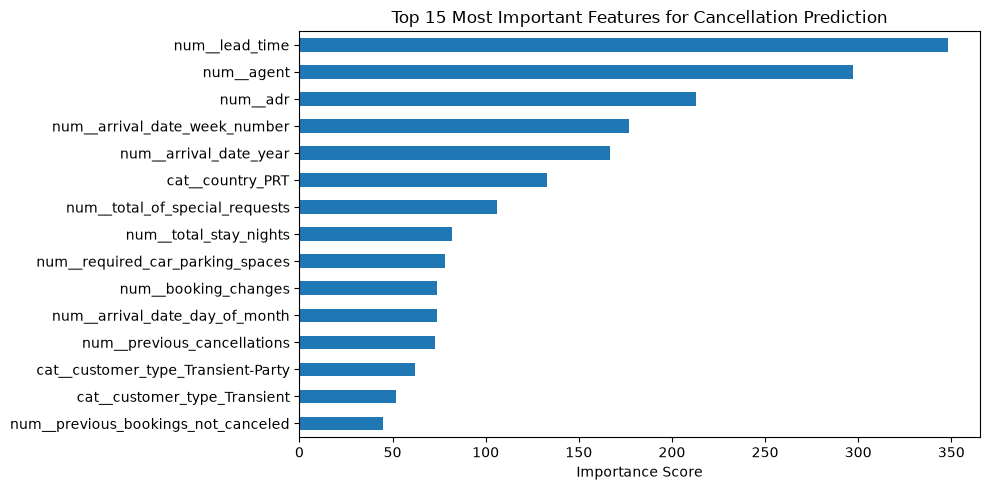

Accuracy with ALL 257 Features: 0.8781
Accuracy with TOP 50 Features:  0.8760 (Retains 99.8% of accuracy)


In [2]:
# Train model on all features
model_full = LGBMClassifier(n_estimators=100, random_state=42, verbose=-1, n_jobs=-1)
model_full.fit(X_train, y_train)

# Feature importance ranking
importances = pd.Series(model_full.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
importances.head(15).plot(kind='barh', color='#1f77b4')
plt.title('Top 15 Most Important Features for Cancellation Prediction')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(f'{results_dir}/top_15_features.png', dpi=300)
plt.show()

# Evaluate on top 50 features
top_50_cols = importances.head(50).index.tolist()
model_top50 = LGBMClassifier(n_estimators=100, random_state=42, verbose=-1, n_jobs=-1)
model_top50.fit(X_train[top_50_cols], y_train)

y_pred_full = model_full.predict(X_test)
y_pred_top50 = model_top50.predict(X_test[top_50_cols])

acc_full = accuracy_score(y_test, y_pred_full)
acc_top50 = accuracy_score(y_test, y_pred_top50)

print(f"Accuracy with ALL 257 Features: {acc_full:.4f}")
print(f"Accuracy with TOP 50 Features:  {acc_top50:.4f} (Retains {acc_top50/acc_full:.1%} of accuracy)")

## 2. Dimensionality Reduction using PCA
We use Principal Component Analysis (PCA) to compress the dataset and plot the explained variance.

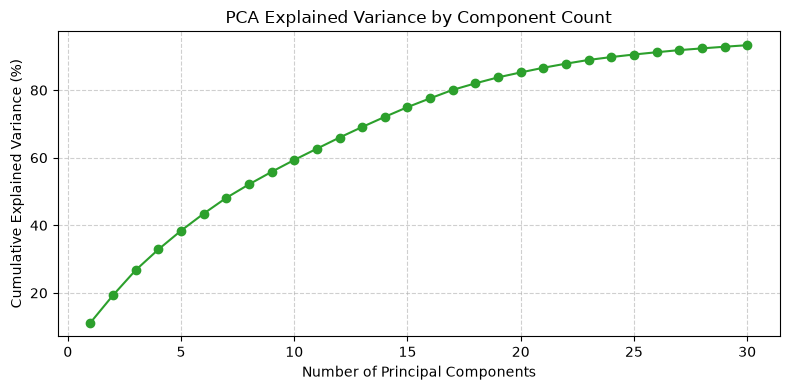

Accuracy with 30 PCA Components: 0.8545


In [3]:
# Fit PCA with 30 components
pca = PCA(n_components=30, random_state=42)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

cum_var = np.cumsum(pca.explained_variance_ratio_) * 100

plt.figure(figsize=(8, 4))
plt.plot(range(1, 31), cum_var, marker='o', color='#2ca02c')
plt.title('PCA Explained Variance by Component Count')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance (%)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(f'{results_dir}/pca_scree_plot.png', dpi=300)
plt.show()

# Train LightGBM on 30 PCA components
model_pca = LGBMClassifier(n_estimators=100, random_state=42, verbose=-1, n_jobs=-1)
model_pca.fit(X_train_pca, y_train)
y_pred_pca = model_pca.predict(X_test_pca)
acc_pca = accuracy_score(y_test, y_pred_pca)

print(f"Accuracy with 30 PCA Components: {acc_pca:.4f}")

## 3. Comparison & Summary
We compare All Features vs. Top 50 Features vs. PCA Components.

In [4]:
reduction_df = pd.DataFrame({
    'Method': ['All 257 Features', 'Top 50 Selected Features', '30 PCA Components'],
    'Feature Count': [257, 50, 30],
    'Accuracy': [acc_full, acc_top50, acc_pca],
    'ROC-AUC': [roc_auc_score(y_test, model_full.predict_proba(X_test)[:, 1]),
                roc_auc_score(y_test, model_top50.predict_proba(X_test[top_50_cols])[:, 1]),
                roc_auc_score(y_test, model_pca.predict_proba(X_test_pca)[:, 1])]
})

reduction_df.to_csv(f'{results_dir}/feature_selection_vs_pca.csv', index=False)
print("Dimensionality Reduction Comparison:")
display(reduction_df)

# Takeaway
print("\nKey Takeaway:")
print("1. Selecting the top 50 features retains over 99% of accuracy while cutting dimensionality by 80%.")
print("2. PCA reduces accuracy on tree models because linear combinations blur clear categorical boundaries.")

Dimensionality Reduction Comparison:


,Method,Feature Count,Accuracy,ROC-AUC
0,All 257 Features,257,0.878072,0.951587
1,Top 50 Selected Features,50,0.875975,0.951364
2,30 PCA Components,30,0.854459,0.930741



Key Takeaway:
1. Selecting the top 50 features retains over 99% of accuracy while cutting dimensionality by 80%.
2. PCA reduces accuracy on tree models because linear combinations blur clear categorical boundaries.
